# Diabetes 130-US Hospitals — Readmission Analysis

## Project Overview

This project analyzes the **Diabetes 130-US Hospitals for Years 1999–2008** dataset to explore factors associated with hospital readmission.

## Objectives

* Understand and clean the hospital admission data
* Explore patient, hospitalization, diagnosis, and treatment patterns
* Analyze factors associated with readmission
* Build a classification model to predict readmission
* Evaluate model performance
* Communicate key findings through visualizations

## Tools & Technologies

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Scikit-learn
* JupyterLab

## Dataset

**Diabetes 130-US Hospitals for Years 1999–2008**

The dataset contains hospital admission records for diabetic patients and includes demographic, hospitalization, diagnosis, medication, and readmission information.

## Project Workflow

**Data Loading → Data Cleaning → Exploratory Data Analysis → Feature Preparation → Machine Learning → Model Evaluation → Insights & Conclusion**


In [105]:
# Data analysis
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Utilities
import os
from datetime import datetime

In [9]:
import zipfile

zip_file = "diabetes+130-us+hospitals+for+years+1999-2008.zip"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("diabetes_data")

In [10]:
import os

os.listdir("diabetes_data")

['diabetic_data.csv', 'IDS_mapping.csv']

In [11]:
df = pd.read_csv("diabetes_data/diabetic_data.csv")

In [12]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [13]:
df.shape

(101766, 50)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [15]:
df.isna().sum().sort_values(ascending=False)

max_glu_serum               96420
A1Cresult                   84748
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
encounter_id                    0
patient_nbr                     0
number_inpatient                0
number_emergency                0
diag_1                          0
diag_2                          0
number_diagnoses                0
diag_3                          0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [16]:
df.isna().mean().sort_values(ascending=False)*100

max_glu_serum               94.746772
A1Cresult                   83.277322
race                         0.000000
gender                       0.000000
age                          0.000000
weight                       0.000000
admission_type_id            0.000000
discharge_disposition_id     0.000000
admission_source_id          0.000000
time_in_hospital             0.000000
payer_code                   0.000000
medical_specialty            0.000000
num_lab_procedures           0.000000
num_procedures               0.000000
num_medications              0.000000
number_outpatient            0.000000
encounter_id                 0.000000
patient_nbr                  0.000000
number_inpatient             0.000000
number_emergency             0.000000
diag_1                       0.000000
diag_2                       0.000000
number_diagnoses             0.000000
diag_3                       0.000000
metformin                    0.000000
repaglinide                  0.000000
nateglinide 

In [17]:
(df == "?").sum().sort_values(ascending=False)

weight                      98569
medical_specialty           49949
payer_code                  40256
race                         2273
diag_3                       1423
diag_2                        358
diag_1                         21
admission_type_id               0
patient_nbr                     0
encounter_id                    0
time_in_hospital                0
admission_source_id             0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
discharge_disposition_id        0
gender                          0
age                             0
number_inpatient                0
number_emergency                0
number_outpatient               0
number_diagnoses                0
max_glu_serum                   0
A1Cresult                       0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [18]:
df = df.replace("?", np.nan)

In [19]:
df.isna().mean().sort_values(ascending=False) * 100

weight                      96.858479
max_glu_serum               94.746772
A1Cresult                   83.277322
medical_specialty           49.082208
payer_code                  39.557416
race                         2.233555
diag_3                       1.398306
diag_2                       0.351787
diag_1                       0.020636
patient_nbr                  0.000000
time_in_hospital             0.000000
admission_source_id          0.000000
num_lab_procedures           0.000000
encounter_id                 0.000000
admission_type_id            0.000000
discharge_disposition_id     0.000000
gender                       0.000000
age                          0.000000
number_inpatient             0.000000
number_emergency             0.000000
number_outpatient            0.000000
num_medications              0.000000
num_procedures               0.000000
number_diagnoses             0.000000
metformin                    0.000000
repaglinide                  0.000000
nateglinide 

In [20]:
df = df.drop("weight",axis=1) 

In [21]:
df["max_glu_serum"] = df["max_glu_serum"].fillna("Not Tested")
df["A1Cresult"] = df["A1Cresult"].fillna("Not Tested")

df["medical_specialty"] = df["medical_specialty"].fillna("Unknown")
df["payer_code"] = df["payer_code"].fillna("Unknown")
df["race"] = df["race"].fillna("Unknown")

df["diag_1"] = df["diag_1"].fillna("Unknown")
df["diag_2"] = df["diag_2"].fillna("Unknown")
df["diag_3"] = df["diag_3"].fillna("Unknown")

In [22]:
df.isna().sum().sort_values(ascending=False)

encounter_id                0
patient_nbr                 0
race                        0
gender                      0
age                         0
admission_type_id           0
discharge_disposition_id    0
admission_source_id         0
time_in_hospital            0
payer_code                  0
medical_specialty           0
num_lab_procedures          0
num_procedures              0
num_medications             0
number_outpatient           0
number_emergency            0
number_inpatient            0
diag_1                      0
diag_2                      0
diag_3                      0
number_diagnoses            0
max_glu_serum               0
A1Cresult                   0
metformin                   0
repaglinide                 0
nateglinide                 0
chlorpropamide              0
glimepiride                 0
acetohexamide               0
glipizide                   0
glyburide                   0
tolbutamide                 0
pioglitazone                0
rosiglitaz

In [23]:
df.duplicated().sum()

np.int64(0)

In [24]:
df["patient_nbr"].nunique()

71518

In [25]:
patient_counts = df["patient_nbr"].value_counts()

(patient_counts > 1).sum()

np.int64(16773)

In [26]:
patient_counts.head(12)

patient_nbr
88785891    40
43140906    28
1660293     23
23199021    23
88227540    23
23643405    22
84428613    22
92709351    21
90609804    20
89472402    20
23398488    20
37096866    20
Name: count, dtype: int64

In [27]:
df["gender"].value_counts()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

In [28]:
df["gender"] = df["gender"].replace("Unknown/Invalid", "Unknown")

In [29]:
gender_readmission = pd.crosstab(
    df["gender"],
    df["readmitted"],
    normalize="index"
) * 100

gender_readmission

readmitted,<30,>30,NO
gender,,,
Female,11.245156,35.676683,53.078160
Male,11.061524,34.060142,54.878334
Unknown,0.000000,0.000000,100.000000


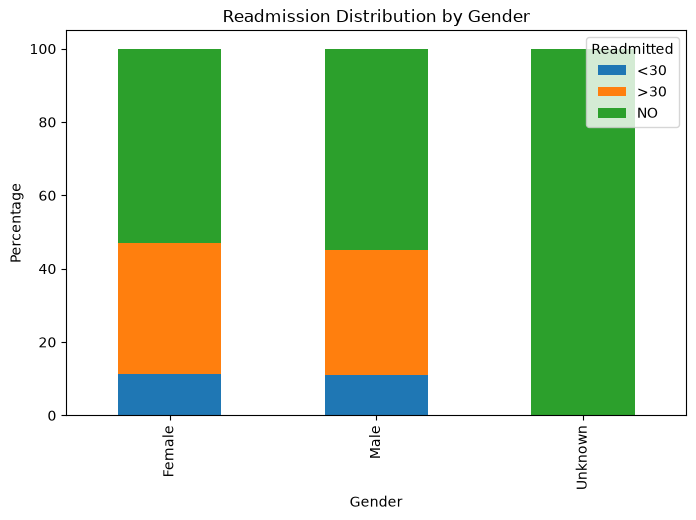

In [30]:
gender_readmission.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Readmission Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage")
plt.legend(title="Readmitted")
plt.show()

In [31]:
df.groupby("readmitted")["time_in_hospital"].mean()

readmitted
<30    4.768249
>30    4.495541
NO     4.254429
Name: time_in_hospital, dtype: float64

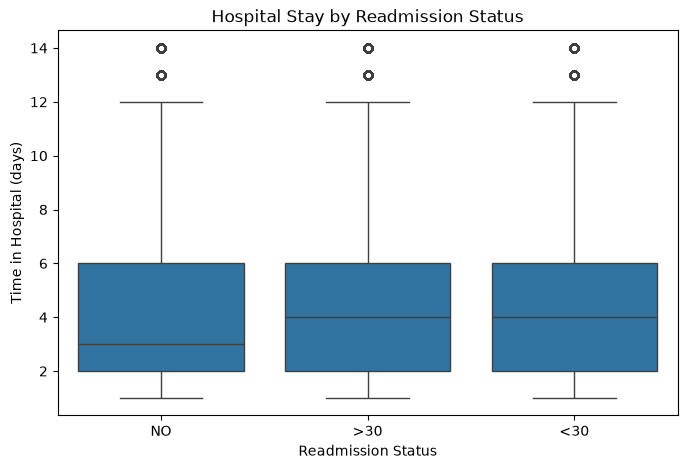

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="readmitted",
    y="time_in_hospital"
)

plt.title("Hospital Stay by Readmission Status")
plt.xlabel("Readmission Status")
plt.ylabel("Time in Hospital (days)")

plt.show()

### Finding — Hospital Stay and Readmission

Hospital stay distributions were broadly similar across readmission groups. Patients who were readmitted had slightly higher median hospital stays than patients who were not readmitted, while the overall spread was similar across groups.


In [33]:
df["age"].value_counts().sort_index()

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

In [34]:
df["encounter_id"].nunique()

101766

In [35]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [36]:
df["readmitted"].value_counts(normalize=True) * 100

readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64

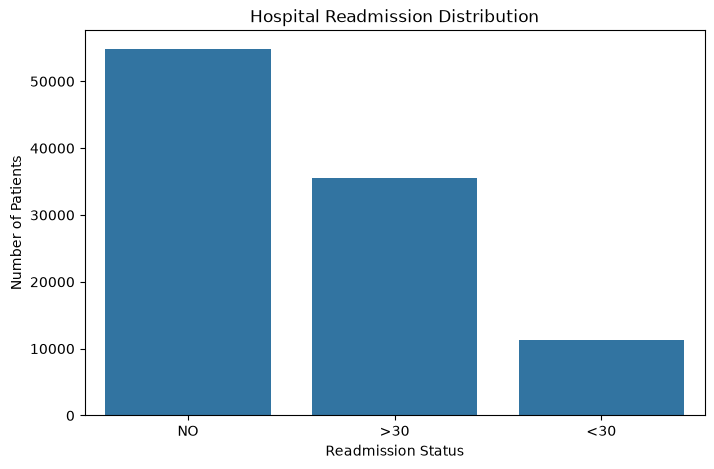

In [37]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="readmitted")

plt.title("Hospital Readmission Distribution")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Patients")

plt.show()

In [38]:
pd.crosstab(df["age"], df["readmitted"],normalize="index") * 100

readmitted,<30,>30,NO
age,,,
[0-10),1.863354,16.149068,81.987578
[10-20),5.788712,32.416787,61.794501
[20-30),14.242607,30.778515,54.978877
[30-40),11.231788,31.443709,57.324503
[40-50),10.604027,33.846154,55.549819
[50-60),9.666203,34.289522,56.044274
[60-70),11.128408,35.124316,53.747276
[70-80),11.773055,36.347246,51.879699
[80-90),12.083503,36.186544,51.729953


In [39]:
age_readmission = pd.crosstab(df["age"], df["readmitted"],normalize="index") * 100

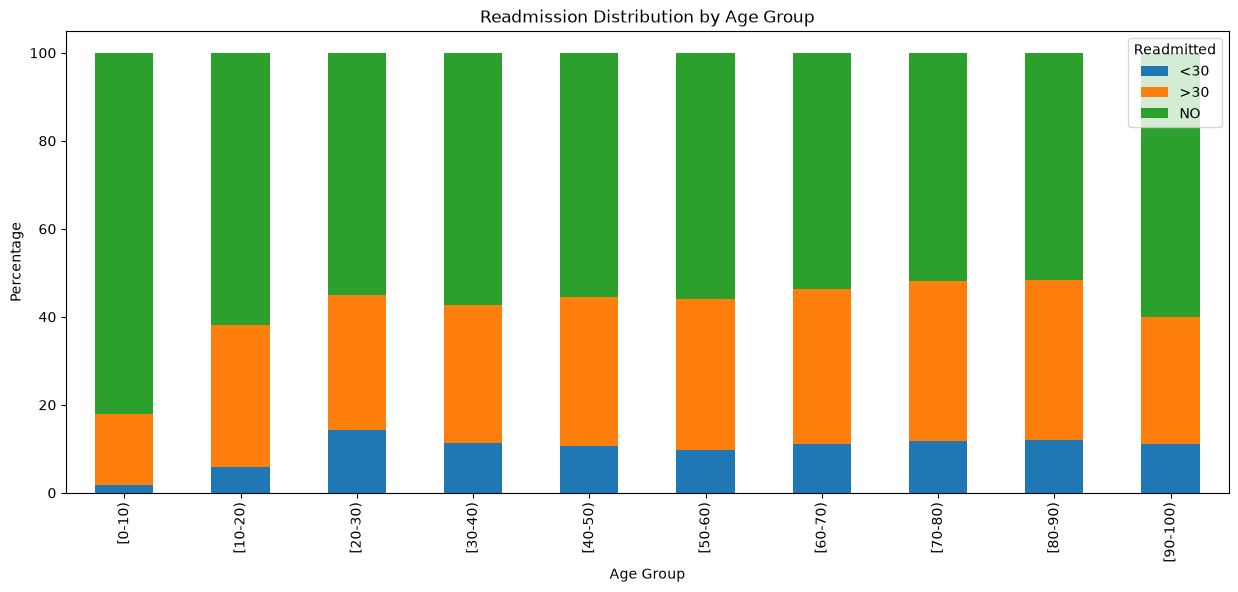

In [40]:
age_readmission.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 6)
)

plt.title("Readmission Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")
plt.legend(title="Readmitted")
plt.show()

In [41]:
df["race"].value_counts()

race
Caucasian          76099
AfricanAmerican    19210
Unknown             2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

In [42]:
race_readmission = pd.crosstab(
    df["race"],
    df["readmitted"],
    normalize="index"
) * 100

race_readmission

readmitted,<30,>30,NO
race,,,
AfricanAmerican,11.218116,34.534097,54.247788
Asian,10.140406,25.117005,64.742590
Caucasian,11.290556,35.643044,53.066400
Hispanic,10.407462,31.516937,58.075601
Other,9.628154,29.614874,60.756972
Unknown,8.271007,23.669160,68.059833


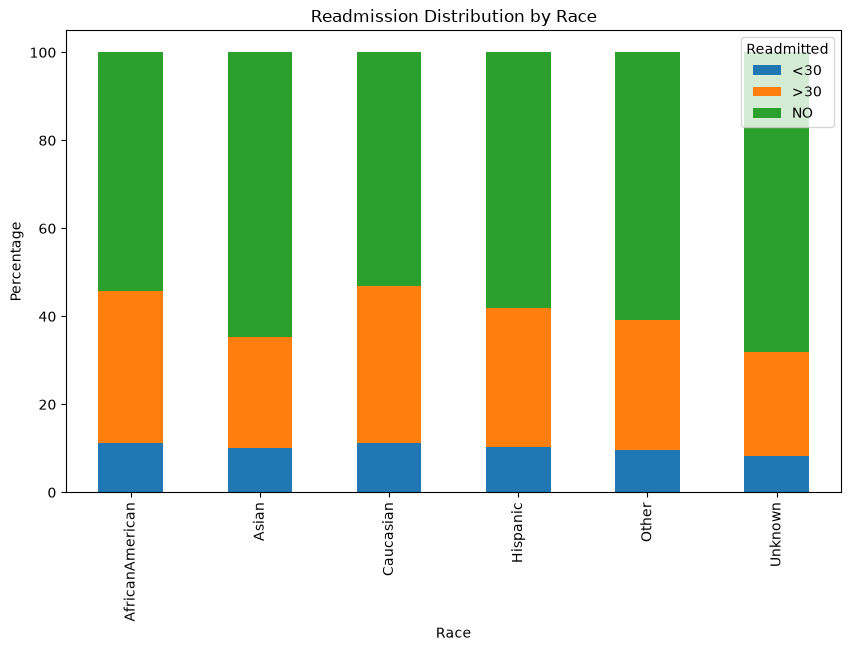

In [43]:
race_readmission.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Readmission Distribution by Race")
plt.xlabel("Race")
plt.ylabel("Percentage")
plt.legend(title="Readmitted")
plt.show()

### Finding — Race and Readmission

Readmission patterns varied across race groups. The Caucasian group had the highest proportion of readmission after 30 days (35.64%), while the proportion of readmission within 30 days was relatively similar across the major race groups. These results indicate an association between race and readmission patterns, but they do not establish causation.

In [44]:
df["number_inpatient"].value_counts().sort_index()

number_inpatient
0     67630
1     19521
2      7566
3      3411
4      1622
5       812
6       480
7       268
8       151
9       111
10       61
11       49
12       34
13       20
14       10
15        9
16        6
17        1
18        1
19        2
21        1
Name: count, dtype: int64

In [45]:
df.groupby("readmitted")["number_inpatient"].mean()

readmitted
<30    1.224003
>30    0.838993
NO     0.381963
Name: number_inpatient, dtype: float64

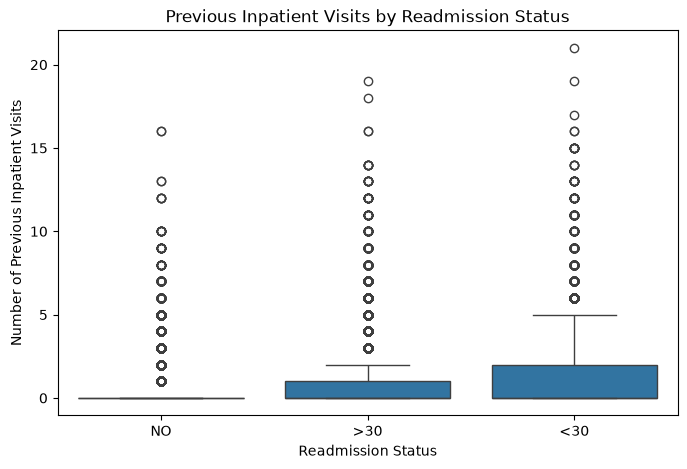

In [46]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="readmitted",
    y="number_inpatient"
)

plt.title("Previous Inpatient Visits by Readmission Status")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Previous Inpatient Visits")

plt.show()

### Finding — Previous Inpatient Visits and Readmission

Patients who were readmitted had a higher average number of previous inpatient visits than patients who were not readmitted. The highest average was observed for patients readmitted within 30 days (1.22 visits), compared with 0.84 visits for readmission after 30 days and 0.38 visits for patients who were not readmitted.


In [47]:
df["number_emergency"].value_counts().sort_index()

number_emergency
0     90383
1      7677
2      2042
3       725
4       374
5       192
6        94
7        73
8        50
9        33
10       34
11       23
12       10
13       12
14        3
15        3
16        5
18        5
19        4
20        4
21        2
22        6
24        1
25        2
28        1
29        1
37        1
42        1
46        1
54        1
63        1
64        1
76        1
Name: count, dtype: int64

In [48]:
df.groupby("readmitted")["number_emergency"].mean()

readmitted
<30    0.357313
>30    0.283669
NO     0.109216
Name: number_emergency, dtype: float64

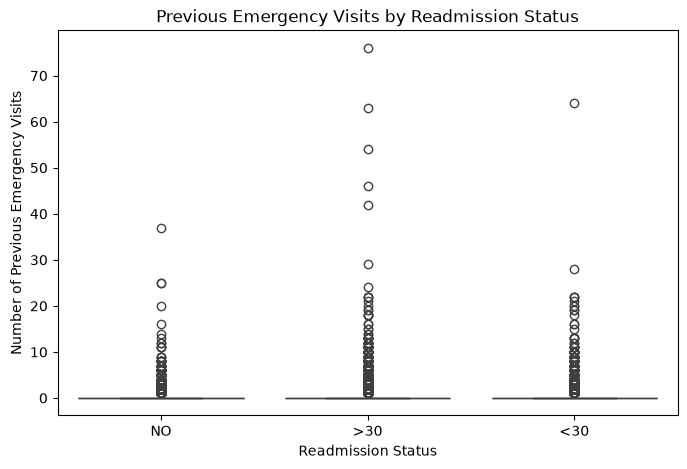

In [49]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="readmitted",
    y="number_emergency"
)

plt.title("Previous Emergency Visits by Readmission Status")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Previous Emergency Visits")

plt.show()

### Finding — Previous Emergency Visits and Readmission

Patients who were readmitted had higher average numbers of previous emergency visits than patients who were not readmitted. The highest average was observed for patients readmitted within 30 days (0.357 visits), compared with 0.284 visits for readmission after 30 days and 0.109 visits for patients who were not readmitted.


In [77]:
df["readmitted_30d"] = (df["readmitted"] == "<30").astype(int)

In [78]:
df["readmitted_30d"].value_counts()

readmitted_30d
0    90409
1    11357
Name: count, dtype: int64

In [79]:
df["readmitted_30d"].value_counts(normalize=True) * 100

readmitted_30d
0    88.840084
1    11.159916
Name: proportion, dtype: float64

In [80]:
X = df.drop(
    ["readmitted", "readmitted_30d", "encounter_id", "patient_nbr"],
    axis=1
)

y = df["readmitted_30d"]

In [81]:
X.shape

(101766, 46)

In [82]:
from sklearn.model_selection import GroupShuffleSplit

In [83]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups=df["patient_nbr"]
    )
)

In [84]:
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [85]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(81613, 46)
(20153, 46)
(81613,)
(20153,)


In [86]:
train_patients = set(df.iloc[train_idx]["patient_nbr"])
test_patients = set(df.iloc[test_idx]["patient_nbr"])

len(train_patients.intersection(test_patients))

0

In [87]:
numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

In [88]:
categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

In [89]:
print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 8
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical features: 38
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [90]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [91]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [92]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [93]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [94]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [95]:
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](46,)","['race','gender','age',...,'metformin-pioglitazone','change','diabetesMed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,46
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, 

In [96]:
y_pred = logistic_pipeline.predict(X_test)

In [97]:
y_pred[:10]

array([1, 1, 1, 0, 0, 0, 0, 1, 0, 0])

In [98]:
comparison = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": y_pred[:10]
})

comparison

,Actual,Predicted
0,0,1
1,0,1
2,0,1
3,0,0
4,0,0
5,0,0
6,0,0
7,1,1
8,0,0
9,1,0


In [99]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

cm

array([[12032,  5970],
       [  954,  1197]])

In [100]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.6564283233265519
Precision: 0.16701548765173713
Recall: 0.5564853556485355
F1 Score: 0.25692208628461044


### Logistic Regression — Initial Model Evaluation

The Logistic Regression model achieved an accuracy of 65.64%, precision of 16.70%, recall of 55.65%, and an F1-score of 25.69%.

The model identified approximately 55.65% of actual readmissions within 30 days. However, its low precision indicates a high number of false-positive predictions.

Overall, the model demonstrates some ability to identify readmissions, but its predictive performance needs improvement.


In [101]:
print(classification_report(
    y_test,
    y_pred,
    target_names=[
        "Not Readmitted Within 30 Days",
        "Readmitted Within 30 Days"
    ]
))

                               precision    recall  f1-score   support

Not Readmitted Within 30 Days       0.93      0.67      0.78     18002
    Readmitted Within 30 Days       0.17      0.56      0.26      2151

                     accuracy                           0.66     20153
                    macro avg       0.55      0.61      0.52     20153
                 weighted avg       0.85      0.66      0.72     20153



### Classification Report — Model Performance

The Logistic Regression model performed better at identifying patients who were not readmitted within 30 days than those who were readmitted.

For the readmission class, the model achieved 17% precision and 56% recall, indicating that it identified approximately 56% of actual readmissions but generated a considerable number of false-positive predictions.

The results show that the model has limitations, particularly in accurately identifying readmission cases.

In [102]:
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.6557712916964493


### ROC-AUC Evaluation

The Logistic Regression model achieved a ROC-AUC score of 0.656, indicating limited ability to distinguish between patients readmitted within 30 days and those not readmitted within 30 days.

Although the model performs better than random ranking, its predictive performance remains limited and requires improvement before any practical application.


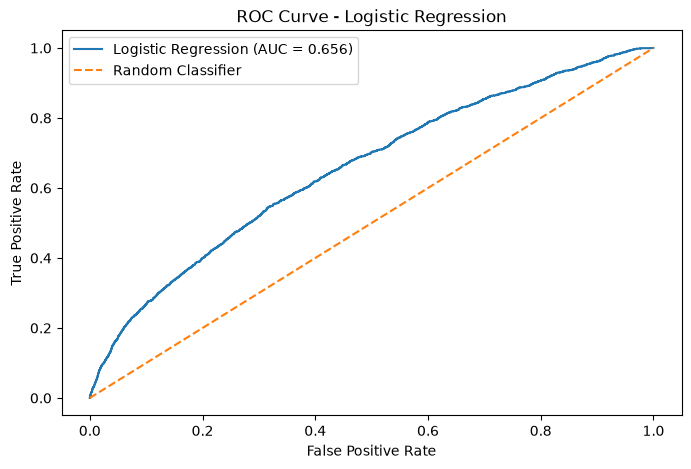

In [103]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

#  Business Insights

## Key Findings

1. **Overall Readmission:** Approximately 11.16% of hospital encounters resulted in readmission within 30 days.

2. **Age:** The 20–30 age group had the highest observed proportion of readmission within 30 days (14.24%). However, this group had fewer records than older age groups.

3. **Gender:** Male and female readmission patterns were very similar, with 11.06% and 11.25% readmission within 30 days, respectively.

4. **Race:** Readmission patterns varied across race categories, although the differences should be interpreted carefully because the groups had different sample sizes.

5. **Hospital Stay:** Encounters followed by readmission within 30 days had an average hospital stay of 4.77 days, compared with 4.25 days for encounters with no readmission.

6. **Previous Inpatient Visits:** The average number of previous inpatient visits was higher among encounters followed by readmission within 30 days (1.22) than among encounters with no readmission (0.38).

7. **Previous Emergency Visits:** Encounters followed by readmission within 30 days also had more previous emergency visits on average (0.357) than encounters with no readmission (0.109).

#  Business Recommendations

Based on the analysis, the following recommendations could help hospitals review their readmission patterns and improve patient-care processes.

1. **Review Previous Hospitalizations:** Patients with a history of previous inpatient and emergency visits showed higher readmission proportions. Hospitals could review these patients' discharge plans and follow-up arrangements.

2. **Strengthen Discharge Planning:** Encounters associated with readmission had a slightly longer average hospital stay. Hospitals could examine discharge processes and identify opportunities for better continuity of care.

3. **Improve Follow-up Processes:** Hospitals could review follow-up appointment scheduling and post-discharge communication, particularly for patients with previous hospital visits.

4. **Monitor Readmission Patterns:** Hospitals should regularly monitor readmission rates across age groups and other patient categories to identify patterns and investigate possible service gaps.

5. **Improve Predictive Model Performance:** The Logistic Regression model showed limited predictive performance. Further validation and improvement would be needed before considering it for operational use.

#  Project Limitations

1. **Historical Dataset:** The dataset covers hospital encounters from 1999–2008. Healthcare practices and technologies may have changed since then.

2. **Missing Information:** Several columns had substantial missing data. Some columns were removed, while others were assigned categories such as "Unknown" and "Not Tested". These treatments may affect the analysis.

3. **Class Imbalance:** Only 11.16% of encounters belonged to the within-30-day readmission category, making prediction challenging.

4. **Model Performance:** The Logistic Regression model achieved a ROC-AUC score of 0.656 and low precision, indicating limited predictive ability.

5. **Association vs Causation:** The analysis identifies relationships between patient characteristics and readmission patterns but does not establish that any factor causes readmission.

6. **Limited Model Testing:** Only one classification model was developed, without extensive hyperparameter tuning or cross-validation.

7. **Generalizability:** The findings come from a historical US hospital dataset and may not represent current healthcare settings or other populations.

#  Conclusion

This project analyzed the Diabetes 130-US Hospitals dataset (1999–2008) to explore factors associated with hospital readmission and develop a basic classification model to predict readmission within 30 days.

The analysis covered patient demographics, hospital stay duration, previous inpatient visits, emergency visits, and other healthcare-related variables.

Key findings showed that approximately 11.16% of hospital encounters resulted in readmission within 30 days. Encounters associated with readmission within 30 days also had higher average numbers of previous inpatient and emergency visits compared with encounters without readmission.

A Logistic Regression model was developed to predict readmission within 30 days. It achieved an accuracy of 65.64%, recall of 55.65%, and ROC-AUC score of 0.656. However, its low precision of 16.70% indicates that the model generated many false-positive predictions.

Overall, this project provided practical experience in data cleaning, exploratory data analysis, data visualization, feature preparation, machine learning, and model evaluation.

The findings highlight patterns worth investigating further, while the model's limitations show the importance of additional validation and improvement before any practical use.